# Escenarios, ponderaciones y la no linealidad de la PCE

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 y 02 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- escribir la PD a un punto en el tiempo como función de un factor sistemático y convertir entre una tasa de incumplimiento y el factor que implica;
- mostrar con números por qué la PD ponderada por probabilidad no es la PD del escenario promedio, y por qué un escenario «base» en $z = 0$ es la mediana y no la media;
- verificar la integración de Gauss-Hermite sobre el factor y decir cuántos nodos necesita la identidad del motor;
- ponderar la PCE de tres escenarios, reproducir los totales por etapa versionados y leer la sensibilidad a las ponderaciones como una derivada lineal exacta;
- distinguir los dos índices de no linealidad (el de la PD y el de la PCE) y medir qué agrega la reasignación de etapas cuando se mueven las ponderaciones.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C06 a la fecha de reporte 2008-12-31 (préstamos 7(a) de la SBA, Obras del Gobierno de EE. UU., clase de licencia `mirror-allowed`; los escenarios macroeconómicos son formas de las trayectorias de la prueba de estrés 2026 de la Reserva Federal, mirror-allowed). Se lee un archivo, `data/derived/C06/rd-2008-12.json`:

- `outputs.scenarios`: tres escenarios con su ponderación y su factor sistemático medio $z$;
- `outputs.ecl_by_scenario`: la PCE de cada escenario y etapa, con las etapas fijas en la asignación ponderada;
- `outputs.weight_grid`: quince vectores de ponderaciones en una grilla de paso 0,25, con la PCE **con las etapas congeladas** y la PCE **con las etapas recalculadas** con esas ponderaciones;
- `outputs.non_linearity`: la comparación, a nivel de PD y a nivel de PCE, de la medida ponderada con la trayectoria media, y la curva de la PD condicional contra $z$.

La celda siguiente carga el artefacto e imprime los escenarios, las ponderaciones y las versiones del motor.

In [2]:
# Cargar el artefacto de la fecha de reporte y listar sus escenarios con sus ponderaciones y factores
from riskvalidation.provisions import ecl as ecl_engine, term_structure as tsm
from riskvalidation.validation import ifrs9

LANG = "es"
ROOT = Path("../../..").resolve()
case = json.loads((ROOT / "data" / "derived" / "C06" / "rd-2008-12.json").read_text(encoding="utf-8"))
out = case["outputs"]

for s in out["scenarios"]:
    print(f"{s['id']:18s} ponderación: {s['weight']:.2f} | factor medio z: {s['z_mean']:.4f} | {s['label'][LANG]}")
print("motor que calculó el artefacto:", case["provenance"]["riskvalidation_version"], "| motor instalado:", md.version("riskvalidation"))
print("hallazgos del artefacto:", [f["id"] for f in case["findings"]])

baseline           ponderación: 0.60 | factor medio z: -1.4801 | Base (forma Fed 2026)
adverse            ponderación: 0.30 | factor medio z: -1.3735 | Adverso (punto medio de las formas Fed, propio de Contraste)
severely-adverse   ponderación: 0.10 | factor medio z: -1.3478 | Severamente adverso (forma Fed 2026)
motor que calculó el artefacto: 0.5.0 | motor instalado: 0.9.0
hallazgos del artefacto: ['F-SICR-amber', 'F-MIGRATION-red', 'F-SCENARIO-ORDER', 'F-NO-DELINQUENCY', 'F-LGD-PROXY', 'F-EAD-MODEL', 'F-PREPAYMENT', 'F-SHORT-LIFE']


## Método

IFRS 9 pide un monto insesgado y ponderado por probabilidad (5.5.17(a)), construido con más de un escenario cuando la pérdida no es lineal en la trayectoria macroeconómica (B5.5.41 y B5.5.42; GPPC 2016, sección 2.8.1.2). Tres resultados sostienen este cuaderno.

**1. La PD condicional.** En el modelo de un factor de la fórmula IRB (BCBS 2005, sección 4.2; Gordy 2003), un deudor incumple cuando su retorno de activos, $\sqrt{\rho}\,Z + \sqrt{1-\rho}\,\varepsilon$, cae bajo $\Phi^{-1}(PD^{\mathrm{TTC}})$, con $Z$ y $\varepsilon$ normales estándar e independientes. La PD dado el factor sistemático $z$ es

$$PD^{\mathrm{PIT}}(z) = \Phi\!\left(\frac{\Phi^{-1}(PD^{\mathrm{TTC}}) - \sqrt{\rho}\,z}{\sqrt{1-\rho}}\right), \qquad \mathbb{E}_Z\bigl[PD^{\mathrm{PIT}}(Z)\bigr] = PD^{\mathrm{TTC}}$$

y su inversa da el factor implicado por una tasa de incumplimiento observada $DR$: $z = \bigl(\Phi^{-1}(PD^{\mathrm{TTC}}) - \sqrt{1-\rho}\,\Phi^{-1}(DR)\bigr)/\sqrt{\rho}$. Un $z$ negativo es un mal año.

**2. La medida ponderada y su no linealidad.**

$$\mathrm{PCE} = \sum_s w_s\,\mathrm{PCE}_s, \quad w_s \ge 0, \;\sum_s w_s = 1, \qquad \mathrm{NL} = \frac{\mathrm{PCE}_{\mathrm{ponderada}}}{\mathrm{PCE}(\text{trayectoria media})} - 1$$

Como $PD^{\mathrm{PIT}}$ es convexa en $z$ en el rango usual, la desigualdad de Jensen da $\mathbb{E}[PD(Z)] \ge PD(\mathbb{E}[Z])$: la medida ponderada es al menos la medida en el escenario promedio. El BCE (2024) critica los ajustes macro construidos sobre la trayectoria media porque ignoran esta no linealidad y subestiman el impacto medio.

**3. La sensibilidad a las ponderaciones.** La PCE es lineal en las ponderaciones, así que mover ponderación desde un escenario de referencia hacia $s$ la cambia en $\partial\,\mathrm{PCE}/\partial w_s = \mathrm{PCE}_s - \mathrm{PCE}_{\mathrm{ref}}$ (BCBS d350, párrafo 36(a)). Las etapas no son lineales en las ponderaciones cuando la prueba de SICR usa PD ponderadas (GPPC 2016, 2.7.2.10), así que la grilla versionada del motor reporta ambas versiones: etapas congeladas (exactamente lineal) y etapas recalculadas.

Las PCE de un solo escenario al 100 por ciento son sensibilidades, nunca la medida de IFRS 9.

### Paso 1: la curva de PD condicional de la cartera, y su inversa

El artefacto da la $PD^{\mathrm{TTC}}$ y la $\rho$ de la cartera (`non_linearity.parameters`) y la curva versionada de la PD condicional en $z = -3, \dots, 3$. La celda evalúa `ttc_to_pit` en los mismos factores y compara. Luego aplica `implied_z` a las tasas de incumplimiento que da la curva y verifica que los factores vuelven.

In [3]:
# Evaluar la PD condicional en los factores versionados y recuperar los factores con la inversa
nl = out["non_linearity"]
pd_ttc, rho = nl["parameters"]["pd_ttc"], nl["parameters"]["rho"]
z_grid = np.array([p["z"] for p in nl["z_curve"]])
committed_curve = np.array([p["pd_pit"] for p in nl["z_curve"]])
curve = tsm.ttc_to_pit(np.full(z_grid.size, pd_ttc), rho, z_grid)
print("PD_TTC:", round(pd_ttc, 6), "| rho:", rho)
print("PD condicional igual a la curva versionada con tolerancia 1e-9:", si_no(np.allclose(curve, committed_curve, atol=1e-9, rtol=0)))
for z_, p_ in zip(z_grid, curve):
    print("z =", f"{z_:+.0f}", "| PD(z):", round(float(p_), 6))
back = tsm.implied_z(curve, pd_ttc, rho)
print("factores recuperados con la inversa:", si_no(np.allclose(back, z_grid, atol=1e-9, rtol=0)))

PD_TTC: 0.016389 | rho: 0.12
PD condicional igual a la curva versionada con tolerancia 1e-9: sí
z = -3 | PD(z): 0.121428
z = -2 | PD(z): 0.062128
z = -1 | PD(z): 0.028298
z = +0 | PD(z): 0.011432
z = +1 | PD(z): 0.004085
z = +2 | PD(z): 0.001288
z = +3 | PD(z): 0.000358
factores recuperados con la inversa: sí


### Paso 2: un ejemplo trabajado de la no linealidad, y la trampa de la mediana

El ejemplo de referencia del motor viene de la ilustración del dossier: $PD^{\mathrm{TTC}} = 2\%$, $\rho = 0{,}12$, tres escenarios en $z = +1$ (favorable, ponderación 0,25), $z = 0$ (base, 0,50) y $z = -2$ (adverso, 0,25). Son **insumos de la lección**, elegidos para el ejemplo, no datos del C06. La celda calcula la PD condicional de cada escenario con `ttc_to_pit`, la PD ponderada con `weighted_pit_pd`, la PD en el factor promedio ponderado, y la prueba propia del motor `nonlinearity_test`, que devuelve el índice y la verificación de Gauss-Hermite. Con una pérdida dado el incumplimiento de 40 % convierte luego ambas PD en una tasa de pérdida a un año.

In [4]:
# El ejemplo de referencia: tres escenarios, la PD ponderada, la PD en el factor medio y la prueba propia del motor
EX_PD, EX_RHO = 0.02, 0.12  # insumos de la lección
ex_z = np.array([1.0, 0.0, -2.0])
ex_w = np.array([0.25, 0.50, 0.25])
ex_lgd = 0.40

per_scenario = tsm.ttc_to_pit(EX_PD, EX_RHO, ex_z)
weighted = tsm.weighted_pit_pd(EX_PD, EX_RHO, ex_z, ex_w)
mean_z = float(np.sum(ex_w * ex_z))
at_mean = float(tsm.ttc_to_pit(EX_PD, EX_RHO, mean_z))
print("PD condicional por escenario (porcentaje):", np.round(100 * per_scenario, 3))
print("PD ponderada (porcentaje):", round(100 * weighted, 3), "| factor medio ponderado:", mean_z, "| PD en ese factor (porcentaje):", round(100 * at_mean, 3), "| razón:", round(weighted / at_mean, 2))
print("tasa de pérdida, ponderada y en el factor medio (porcentaje):", round(100 * ex_lgd * weighted, 2), round(100 * ex_lgd * at_mean, 2))

test = ifrs9.nonlinearity_test(EX_PD, EX_RHO, ex_z, ex_w, model_id="lesson")
print("prueba del motor, índice:", round(test.metric, 4), "| error de Gauss-Hermite dentro de 1e-9:", si_no(test.extras["gauss_hermite_error"] <= 1e-9), "|", si_no(test.light.value))
print("PD en z = 0 (la mediana) y la PD incondicional (porcentaje):", round(100 * float(per_scenario[1]), 3), round(100 * EX_PD, 3))

PD condicional por escenario (porcentaje): [0.526 1.429 7.342]
PD ponderada (porcentaje): 2.681 | factor medio ponderado: -0.25 | PD en ese factor (porcentaje): 1.8 | razón: 1.49
tasa de pérdida, ponderada y en el factor medio (porcentaje): 1.07 0.72
prueba del motor, índice: 0.4898 | error de Gauss-Hermite dentro de 1e-9: sí | verde
PD en z = 0 (la mediana) y la PD incondicional (porcentaje): 1.429 2.0


### Paso 3: la verificación de Gauss-Hermite

La identidad $\mathbb{E}_Z[PD^{\mathrm{PIT}}(Z)] = PD^{\mathrm{TTC}}$ es la verificación cruzada de la no linealidad del motor. `gauss_hermite_pit_pd` integra la PD condicional sobre la normal estándar con nodos de Gauss-Hermite de los probabilistas. La celda sube el número de nodos e imprime el error contra $PD^{\mathrm{TTC}}$: con pocos nodos la integral es burda, y la documentación promete 1e-9 desde 32 nodos.

In [5]:
# El error de la integral contra PD_TTC al crecer el número de nodos (con piso en 1e-16, el redondeo de la aritmética)
for nodes in (2, 4, 8, 16, 32, 64):
    integral = tsm.gauss_hermite_pit_pd(EX_PD, EX_RHO, nodes)
    print("nodos", f"{nodes:3d}", "| error contra PD_TTC:", f"{max(abs(integral - EX_PD), 1e-16):.0e}")
print("dentro de 1e-9 desde 32 nodos:", si_no(abs(tsm.gauss_hermite_pit_pd(EX_PD, EX_RHO, 32) - EX_PD) <= 1e-9))

nodos   2 | error contra PD_TTC: 2e-04
nodos   4 | error contra PD_TTC: 5e-07
nodos   8 | error contra PD_TTC: 9e-12
nodos  16 | error contra PD_TTC: 1e-16
nodos  32 | error contra PD_TTC: 1e-16
nodos  64 | error contra PD_TTC: 1e-16
dentro de 1e-9 desde 32 nodos: sí


### Paso 4: las mismas dos comparaciones sobre la cartera versionada

De vuelta al C06. El artefacto da los tres factores de escenario y las ponderaciones que usó. La celda recalcula la PD ponderada y la PD en el factor medio ponderado de la cartera con `weighted_pit_pd` y `ttc_to_pit` y las compara con las versionadas. Luego lee el **nivel de la PCE**: la PCE ponderada versionada y la PCE en la trayectoria media dan el índice con `non_linearity_index`. Los dos índices no son la misma cantidad: el primero es sobre una PD a un año de la cartera, el segundo sobre toda la PCE, con trayectorias de vida completa y etapas.

In [6]:
# Recalcular la PD ponderada de la cartera y la PD en el factor medio, y luego el índice a nivel de PCE desde el par versionado
points = nl["scenario_points"]
z_book = np.array([p["z"] for p in points])
w_book = np.array([p["weight"] for p in points])
pd_weighted = tsm.weighted_pit_pd(pd_ttc, rho, z_book, w_book)
pd_mean = float(tsm.ttc_to_pit(pd_ttc, rho, float(np.sum(w_book * z_book))))
print("PD ponderada, motor y versionada:", round(pd_weighted, 8), round(nl["pd_weighted"], 8))
print("PD en el factor medio, motor y versionada:", round(pd_mean, 8), round(nl["pd_at_mean_z"], 8))
pd_index = ecl_engine.non_linearity_index(pd_weighted, pd_mean)
ecl_index = ecl_engine.non_linearity_index(nl["ecl_weighted"], nl["ecl_at_mean_path"])
print("índice a nivel de PD, motor y versionado (la fila de la prueba a nivel de PD):", round(pd_index, 6), [round(t["metric"], 6) for t in case["tests"] if t["test_id"] == "ifrs9.nonlinearity"])
print("índice a nivel de PCE, motor y versionado:", round(ecl_index, 6), round(nl["index"], 6))
print("el índice a nivel de PCE sobre el índice a nivel de PD:", round(ecl_index / pd_index, 1))
print("calculado por el motor", case["provenance"]["riskvalidation_version"], "| leído con el motor", md.version("riskvalidation"))

PD ponderada, motor y versionada: 0.04045198 0.04045198
PD en el factor medio, motor y versionada: 0.04041987 0.04041987
índice a nivel de PD, motor y versionado (la fila de la prueba a nivel de PD): 0.000794 [0.000794]
índice a nivel de PCE, motor y versionado: 0.02121 0.02121
el índice a nivel de PCE sobre el índice a nivel de PD: 26.7
calculado por el motor 0.5.0 | leído con el motor 0.9.0


### Paso 5: ponderar las PCE de los escenarios y reproducir los totales por etapa

`ecl_by_scenario` guarda la PCE de cada escenario por etapa, con las etapas fijas. Apilamos los tres escenarios en un arreglo de forma (escenarios, etapas) y lo ponderamos con `probability_weighted_ecl`. El resultado debe ser igual al `stage_summary` versionado: la cobertura de la cartera a esta fecha. La celda imprime también las PCE de un solo escenario al 100 por ciento (los totales de cada fila), que son sensibilidades y no la medida.

In [7]:
# Ponderar las PCE de los escenarios por etapa y compararlas con los totales por etapa versionados
ids = [s["id"] for s in out["scenarios"]]
weights = np.array([s["weight"] for s in out["scenarios"]])
stages = ("stage1", "stage2", "stage3")
by = {(r["scenario_id"], r["stage"]): r["ecl"] for r in out["ecl_by_scenario"]["rows"]}
matrix = np.array([[by[(sid, st)] for st in stages] for sid in ids])
weighted_by_stage = ecl_engine.probability_weighted_ecl(matrix, weights)
committed = {r["stage"]: r["ecl"] for r in out["stage_summary"]["rows"]}
for st, value in zip(stages, weighted_by_stage):
    print(st, "| ponderada, millones de USD:", round(float(value) / 1e6, 3), "| versionada:", round(committed[st] / 1e6, 3))
single = matrix.sum(axis=1)
for sid, value in zip(ids, single):
    print(f"{sid:18s} PCE al 100 por ciento del escenario, millones de USD: {value / 1e6:9.3f}")
total = float(weighted_by_stage.sum())
print("total ponderado, millones de USD:", round(total / 1e6, 3), "| PCE en la trayectoria media:", round(nl["ecl_at_mean_path"] / 1e6, 3))
print("hallazgo:", [f["title"][LANG] for f in case["findings"] if f["id"] == "F-SCENARIO-ORDER"][0])

stage1 | ponderada, millones de USD: 798.078 | versionada: 798.078
stage2 | ponderada, millones de USD: 68.929 | versionada: 68.929
stage3 | ponderada, millones de USD: 0.0 | versionada: 0.0
baseline           PCE al 100 por ciento del escenario, millones de USD:   897.476
adverse            PCE al 100 por ciento del escenario, millones de USD:   825.460
severely-adverse   PCE al 100 por ciento del escenario, millones de USD:   808.827
total ponderado, millones de USD: 867.007 | PCE en la trayectoria media: 848.999
hallazgo: El escenario severamente adverso da una PCE menor que el base: las sensibilidades macro del hazard tienen el signo equivocado en esta fecha


### Paso 6: la sensibilidad a las ponderaciones, lineal cuando las etapas están congeladas

Con las etapas fijas la PCE es lineal en las ponderaciones, así que `weight_sensitivity` devuelve el cambio exacto de mover ponderación hacia cada escenario desde una referencia. La celda verifica la grilla versionada. Para cada uno de los quince vectores de ponderaciones pondera los totales de un solo escenario con `probability_weighted_ecl` y compara con la `ecl_frozen` versionada: deben ser iguales. Luego imprime, para la grilla versionada, cuánto cambia la PCE cuando las etapas se recalculan con esas ponderaciones y cómo se mueve la proporción de la Etapa 2 en el monto bruto, que es el aporte de las etapas que una sensibilidad lineal no ve.

In [8]:
# Verificar la grilla de etapas congeladas contra la ponderación lineal y medir el aporte de las etapas
grid = out["weight_grid"]["points"]
frozen_engine = np.array([float(ecl_engine.probability_weighted_ecl(single, np.array(p["weights"]))) for p in grid])
frozen_committed = np.array([p["ecl_frozen"] for p in grid])
recomputed = np.array([p["ecl_recomputed"] for p in grid])
print("vectores de ponderaciones en la grilla:", len(grid))
print("la PCE congelada es igual a la ponderación lineal con tolerancia de 1 USD:", si_no(np.allclose(frozen_engine, frozen_committed, atol=1.0, rtol=0)))
sens = ecl_engine.weight_sensitivity(single, 0)
print("cambio de mover toda la ponderación desde el escenario base hacia cada uno, millones de USD:", np.round(sens / 1e6, 3))
difference = recomputed - frozen_committed
print("PCE recalculada menos congelada en la grilla, millones de USD, menor y mayor:", round(float(difference.min()) / 1e6, 3), round(float(difference.max()) / 1e6, 3))
share_frozen = {p["stage2_ratio_frozen"] for p in grid}
share_recomputed = [p["stage2_ratio_recomputed"] for p in grid]
print("proporción de la Etapa 2, congelada (un solo valor):", sorted(round(x, 5) for x in share_frozen), "| recalculada, menor y mayor:", round(min(share_recomputed), 5), round(max(share_recomputed), 5))
for p in grid[:5]:
    print("ponderaciones", p["weights"], "| congelada:", round(p["ecl_frozen"] / 1e6, 2), "| recalculada:", round(p["ecl_recomputed"] / 1e6, 2))

vectores de ponderaciones en la grilla: 15
la PCE congelada es igual a la ponderación lineal con tolerancia de 1 USD: sí
cambio de mover toda la ponderación desde el escenario base hacia cada uno, millones de USD: [  0.    -72.016 -88.65 ]
PCE recalculada menos congelada en la grilla, millones de USD, menor y mayor: -15.235 2.089
proporción de la Etapa 2, congelada (un solo valor): [0.01125] | recalculada, menor y mayor: 0.00779 0.01236
ponderaciones [0.0, 0.0, 1.0] | congelada: 808.83 | recalculada: 793.72
ponderaciones [0.0, 0.25, 0.75] | congelada: 812.99 | recalculada: 797.9
ponderaciones [0.0, 0.5, 0.5] | congelada: 817.14 | recalculada: 801.98
ponderaciones [0.0, 0.75, 0.25] | congelada: 821.3 | recalculada: 806.07
ponderaciones [0.0, 1.0, 0.0] | congelada: 825.46 | recalculada: 810.75


### Paso 7: la curva, la cuerda y la grilla, dibujadas

El panel izquierdo dibuja la PD condicional del ejemplo del paso 2 contra el factor, sus tres puntos de escenario, la PD en el factor medio ponderado (el cuadrado) y la PD ponderada (la línea segmentada): la línea segmentada queda sobre el cuadrado porque la curva se dobla hacia arriba. En la cartera versionada los tres factores están juntos, así que la misma brecha es pequeña y no se vería. El panel derecho dibuja, a lo largo del borde del símplex sin ponderación en el escenario adverso, la PCE con las etapas congeladas (una recta) y con las etapas recalculadas (no es una recta) contra la ponderación del escenario base.

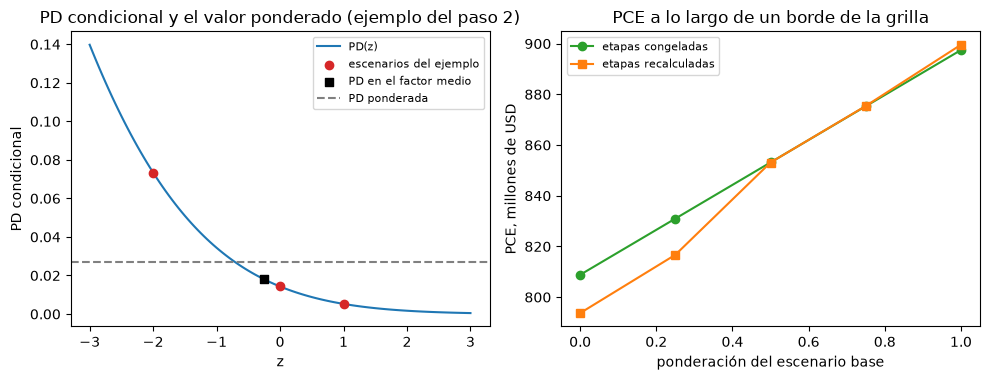

In [9]:
# Dibujar la PD condicional del ejemplo con sus puntos de escenario, y la PCE congelada y recalculada a lo largo de un borde de la grilla de ponderaciones
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.9))
zz = np.linspace(-3.0, 3.0, 121)
left.plot(zz, tsm.ttc_to_pit(np.full(zz.size, EX_PD), EX_RHO, zz), color="tab:blue", label="PD(z)")
left.scatter(ex_z, per_scenario, color="tab:red", zorder=3, label="escenarios del ejemplo")
left.scatter([mean_z], [at_mean], color="black", marker="s", zorder=3, label="PD en el factor medio")
left.axhline(weighted, color="grey", linestyle="--", label="PD ponderada")
left.set_xlabel("z")
left.set_ylabel("PD condicional")
left.set_title("PD condicional y el valor ponderado (ejemplo del paso 2)")
left.legend(fontsize=8)

edge = sorted((p for p in grid if p["weights"][1] == 0.0), key=lambda p: p["weights"][0])
xs = [p["weights"][0] for p in edge]
right.plot(xs, [p["ecl_frozen"] / 1e6 for p in edge], marker="o", color="tab:green", label="etapas congeladas")
right.plot(xs, [p["ecl_recomputed"] / 1e6 for p in edge], marker="s", color="tab:orange", label="etapas recalculadas")
right.set_xlabel("ponderación del escenario base")
right.set_ylabel("PCE, millones de USD")
right.set_title("PCE a lo largo de un borde de la grilla")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **La curva y su inversa cierran.** La PD condicional de la cartera en los siete factores versionados es igual a la curva versionada, de 12,14 % en $z = -3$ a 0,04 % en $z = +3$, e `implied_z` recupera los factores desde las tasas de incumplimiento.
- **La PD ponderada no es la PD del escenario promedio.** En el ejemplo de la lección la PD ponderada es 2,681 % y la PD en el factor medio ponderado ($z = -0{,}25$) es 1,800 %, una razón de 1,49. Con una pérdida dado el incumplimiento de 40 %, la tasa de pérdida a un año es 1,07 % frente a 0,72 % del «escenario promedio». La prueba propia del motor devuelve un índice de 0,4898 y una luz verde, porque su verde significa que la verificación numérica pasó y que el índice no es negativo, no que la no linealidad sea pequeña.
- **El escenario base es la mediana.** La PD en $z = 0$ es 1,429 %, bajo la PD incondicional de 2,000 %. Tratar un caso base en $z = 0$ como la esperanza subestima la PD en cerca de 29 % en este ejemplo.
- **La integral necesita pocos nodos.** El error de Gauss-Hermite contra $PD^{\mathrm{TTC}}$ es cerca de 2e-04 con 2 nodos, 5e-07 con 4 y 9e-12 con 8; desde 16 nodos está en el redondeo de la aritmética (impreso como el piso, 1e-16), así que se cumple el 1e-9 documentado desde 32 nodos.
- **En la cartera versionada las dos comparaciones se reproducen.** El motor da la PD ponderada versionada (0,04045198), la PD en el factor medio (0,04041987), el índice a nivel de PD (0,000794) y el índice a nivel de PCE (0,02121). El índice a nivel de PCE es 26,7 veces el de PD: los tres factores de escenario de la cartera están juntos (de $-1{,}48$ a $-1{,}35$), donde la curva de PD es casi recta, y la PCE es no lineal también por otras razones (trayectorias de vida completa y etapas). El archivo no separa esas causas.
- **Los totales por etapa se reproducen.** Ponderar los tres escenarios da 798,078 millones de USD en la Etapa 1 y 68,929 en la Etapa 2, el `stage_summary` versionado, y un total ponderado de 867,007 millones frente a 848,999 en la trayectoria media. El artefacto lo calculó el motor 0.5.0 y se lee con el 0.8.1; las cifras coinciden.
- **Los escenarios no están ordenados como espera un validador.** La PCE al 100 % de cada escenario es 897,476 millones para el base, 825,460 para el adverso y 808,827 para el severamente adverso: baja a medida que el escenario empeora. El hallazgo versionado `F-SCENARIO-ORDER` dice por qué: las sensibilidades macro del hazard tienen el signo equivocado a esta fecha. Es un hallazgo sobre el modelo, no sobre el motor, que pondera lo que recibe. Una sensibilidad a las ponderaciones leída al pie de la letra dice aquí que mover ponderación hacia el escenario severo baja la cobertura (en 72,016 y 88,650 millones), lo que ningún supervisor aceptaría.
- **La sensibilidad a las ponderaciones es exactamente lineal, y las etapas no.** La PCE con etapas congeladas es igual a la ponderación lineal en los quince puntos de la grilla. Recalcular las etapas con esas ponderaciones cambia la PCE entre $-15{,}235$ y $+2{,}089$ millones y mueve la proporción de la Etapa 2 en el monto bruto entre 0,78 % y 1,24 %, frente a 1,125 % congelada: la parte de la sensibilidad que solo muestra una corrida con reasignación de etapas.

Lo que este cuaderno no muestra: el ejemplo a nivel de PD usa insumos de la lección; si los tres escenarios de Contraste son los correctos es la pregunta del satélite macro (cuaderno 07), y las ponderaciones 0,6, 0,3 y 0,1 son una elección del caso, no una estimación.

## Resumen

- La PD condicional es una función convexa del factor sistemático en el rango usual, así que la PD ponderada por probabilidad es al menos la PD en el escenario promedio; el motor enuncia la identidad, su inversa y una verificación de Gauss-Hermite.
- Un escenario base en $z = 0$ da la PD mediana, no la media; el ejemplo muestra 1,429 % frente a 2,000 %.
- La PCE se pondera escenario por escenario, `probability_weighted_ecl` reproduce los totales por etapa versionados, y los índices a nivel de PCE y de PD son cantidades distintas.
- Con las etapas congeladas la sensibilidad a las ponderaciones es exactamente $\mathrm{PCE}_s - \mathrm{PCE}_{\mathrm{ref}}$; reasignar etapas con las nuevas ponderaciones agrega una parte que una lectura lineal pierde.
- Los escenarios versionados no están ordenados por severidad a esta fecha (hallazgo `F-SCENARIO-ORDER`); un validador lo lee como un hallazgo del modelo antes de leer cualquier sensibilidad.

**Qué probar a continuación.** Cambia `EX_RHO` a 0,04 y a 0,24 y mira la razón entre la PD ponderada y la PD en el factor medio; cambia `ex_w` a ponderaciones iguales. Después sigue con el cuaderno 04, que convierte estas PCE en una cobertura y concilia su movimiento.

## Referencias

- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 de junio de 2016, secciones 2.1.1, 2.7.2 y 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), párrafos 36, 50 y 51 y párrafo A26 del anexo. https://www.bis.org/bcbs/publ/d350.htm
- BCBS (2005), An explanatory note on the Basel II IRB risk weight functions, sección 4.2: el modelo de un factor. https://www.bis.org/publications/explanatory-note-basel-ii-irb-risk-weight-functions.pdf
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3), 199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- ECB Banking Supervision (2024), IFRS 9 overlays and model improvements for novel risks, julio de 2024. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.IFRS9novelrisks_202407~5e0eb30b5c.en.pdf